In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

#202431036_Fathur Rasyid Irimawa

In [3]:
data = pd.read_csv("water_potability.csv")
print(data.head())
data.info()
print(data.describe())

#202431036_Fathur Rasyid Irimawa

         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0       NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2  8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3  8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4  9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   

   Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       10.379783        86.990970   2.963135           0  
1       15.180013        56.329076   4.500656           0  
2       16.868637        66.420093   3.055934           0  
3       18.436524       100.341674   4.628771           0  
4       11.558279        31.997993   4.075075           0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  -

In [6]:
# Fitur: Solids (ppm) dan Conductivity (μS/cm).
# Kedua parameter ini sama-sama merepresentasikan kandungan zat terlarut dalam air, 
# Pengelompokannya punya dasar fisik yang jelas. Hanya memakai dua fitur 
# Hasil clustering-nya langsung bisa di-plot di grafik 2D.
fitur = ['Solids', 'Conductivity']

print(df.corr().round(2))
print("\nKorelasi Solids-Conductivity:", round(df['Solids'].corr(df['Conductivity']), 3))

# Korelasi Solids-Conductivitynya 0,014 (mendekati nol), masing-masing fitur tidak berkorelasi dengan kuat 
# Memberikan informasi yang berbeda. Apabila kedua fiturnya berkorelasi, informasinya akan tumpang tindih dan bobotnya terhitung ganda saat menghitung jarak Euclidean 
# Klaster menjadi condong ke satu dimensi saja.
X = df[fitur]

#202431036_Fathur Rasyid Irimawa

                   ph  Hardness  Solids  Chloramines  Sulfate  Conductivity  \
ph               1.00      0.08   -0.08        -0.03     0.01          0.02   
Hardness         0.08      1.00   -0.05        -0.03    -0.09         -0.02   
Solids          -0.08     -0.05    1.00        -0.07    -0.15          0.01   
Chloramines     -0.03     -0.03   -0.07         1.00     0.02         -0.02   
Sulfate          0.01     -0.09   -0.15         0.02     1.00         -0.01   
Conductivity     0.02     -0.02    0.01        -0.02    -0.01          1.00   
Organic_carbon   0.04      0.00    0.01        -0.01     0.03          0.02   
Trihalomethanes  0.00     -0.01   -0.01         0.02    -0.03          0.00   
Turbidity       -0.04     -0.01    0.02         0.00    -0.01          0.01   

                 Organic_carbon  Trihalomethanes  Turbidity  
ph                         0.04             0.00      -0.04  
Hardness                   0.00            -0.01      -0.01  
Solids                 

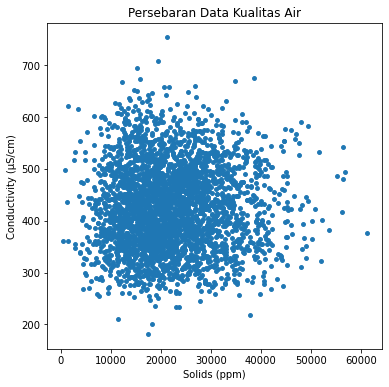

In [7]:
plt.figure(figsize=(6, 6))
plt.scatter(X['Solids'], X['Conductivity'], s=15)
plt.title('Persebaran Data Kualitas Air')
plt.xlabel('Solids (ppm)')
plt.ylabel('Conductivity (μS/cm)')
plt.show()

#202431036_Fathur Rasyid Irimawa

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=fitur)
print("Rata-rata setelah standarisasi:\n", df_scaled.mean().round(4))
print("Simpangan baku setelah standarisasi:\n", 
      df_scaled.std(ddof=0).round(4))

#202431036_Fathur Rasyid Irimawa

Rata-rata setelah standarisasi:
 Solids         -0.0
Conductivity    0.0
dtype: float64
Simpangan baku setelah standarisasi:
 Solids          1.0
Conductivity    1.0
dtype: float64


In [9]:
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X_scaled)
    inertia.append(km.inertia_)
    print(k, round(km.inertia_, 1))

#202431036_Fathur Rasyid Irimawa

D:\Anaconda\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Anaconda\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "D:\Anaconda\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "D:\Anaconda\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\Anaconda\lib\subprocess.py", line 1311, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


1 6552.0
2 4346.7
3 2810.6
4 2240.9
5 1864.6
6 1566.6
7 1357.0
8 1215.0
9 1092.6
10 982.0


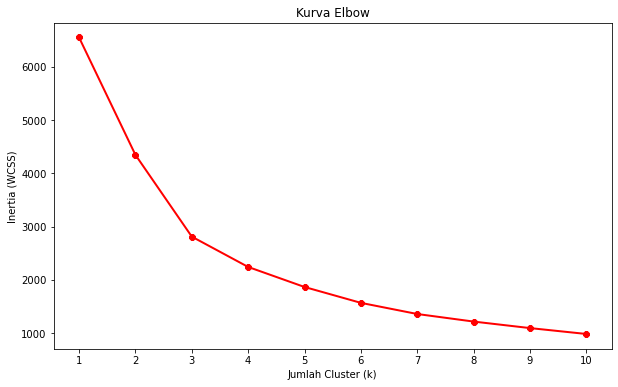

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), inertia, linewidth=2, color='red', marker='8')
plt.title('Kurva Elbow')
plt.xlabel('Jumlah Cluster (k)')
plt.xticks(np.arange(1, 11, 1))
plt.ylabel('Inertia (WCSS)')
plt.show()
# Kandidat k = 3. Inertia turun dari k=1 (6552) ke k=2 (4347) sampai k=3 (2811), sebelum akhirnya menurun di k=4 (2241) dan k=5 (1865). 
# Karena sudut sikunya tidak terlalu tajam seperti data dengan klaster alami, pilihan ini harus divalidasi lagi menggunakan skor silhouette dan DBI.

#202431036_Fathur Rasyid Irimawa

In [11]:
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled)
    hasil.append({'k': k,
                  'Silhouette': round(silhouette_score(X_scaled, km.labels_), 4),
                  'DBI': round(davies_bouldin_score(X_scaled, km.labels_), 4)})
tabel = pd.DataFrame(hasil)
print(tabel)
# Jika silhouette semakin tinggi (mendekati 1) maka semakin bagus, DBI semakin rendah (mendekati 0) maka semakin bagus juga.
# k=3 unggul di skor silhouette yaitu (0,3577) dengan DBI yang jauh lebih baik daripada k=2 dan k=4.
# Nilai DBI k=6 sedikit lebih rendah (0,8777), tapi silhouette-nya turun dan 6 klaster akan lebih susah diinterpretasikan. Jadi gunakan k = 3.

#202431036_Fathur Rasyid Irimawa

   k  Silhouette     DBI
0  2      0.3292  1.2159
1  3      0.3577  0.8979
2  4      0.3430  0.9263
3  5      0.3216  0.9664
4  6      0.3287  0.8777


In [17]:
k_pilih = 3
kmFix = KMeans(n_clusters=k_pilih, n_init=10, random_state=0)
kmFix.fit(X_scaled)
df['label'] = kmFix.labels_

print("Cluster centers terstandarisasi:\n", kmFix.cluster_centers_)
print("\nCluster centers satuan asli:\n",
      pd.DataFrame(scaler.inverse_transform(kmFix.cluster_centers_), columns=fitur))
print("\nJumlah anggota setiap klaster:\n", df['label'].value_counts().sort_index())

#202431036_Fathur Rasyid Irimawa

Cluster centers terstandarisasi:
 [[-0.55251626 -0.70619562]
 [-0.29611713  1.0422168 ]
 [ 1.27687326 -0.1569351 ]]

Cluster centers satuan asli:
          Solids  Conductivity
0  17170.054077    369.136222
1  19417.964851    510.428451
2  33208.737132    413.522914

Jumlah anggota setiap klaster:
 0    1375
1    1056
2     845
Name: label, dtype: int64


In [10]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=['0 tidak layak', '1 layak minum']))

#202431036_Fathur Rasyid Irimawa

Accuracy: 0.652014652014652

Confusion Matrix:
 [[442  57]
 [228  92]]

Classification Report:
                precision    recall  f1-score   support

0 tidak layak       0.66      0.89      0.76       499
1 layak minum       0.62      0.29      0.39       320

     accuracy                           0.65       819
    macro avg       0.64      0.59      0.57       819
 weighted avg       0.64      0.65      0.61       819



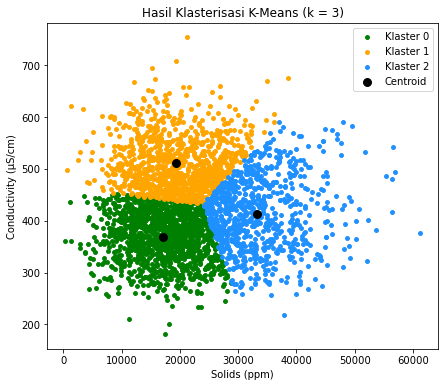

In [14]:
warna = ['green', 'orange', 'dodgerblue']
plt.figure(figsize=(7, 6))
for i in range(k_pilih):
    sub = df[df['label'] == i]
    plt.scatter(sub['Solids'], sub['Conductivity'], s=15, c=warna[i], label=f'Klaster {i}')

pusat = scaler.inverse_transform(kmFix.cluster_centers_)
plt.scatter(pusat[:, 0], pusat[:, 1], s=250, c='black', marker='.', zorder=5, label='Centroid')
plt.title('Hasil Klasterisasi K-Means (k = 3)')
plt.xlabel('Solids (ppm)')
plt.ylabel('Conductivity (μS/cm)')
plt.legend()
plt.show()

#202431036_Fathur Rasyid Irimawa

In [15]:
profil = df.groupby('label')[fitur].mean().round(1)
profil['jumlah'] = df['label'].value_counts().sort_index()
print(profil)
# Penamaan label klaster:
# Klaster 0 (1375 sampel): Air encer (zat terlarut & konduktivitas rendah)
# Klaster 1 (1056 sampel): Air berkonduktivitas tinggi
# Klaster 2 (845 sampel) : Air dengan zat padat terlarut tinggi

#202431036_Fathur Rasyid Irimawa

        Solids  Conductivity  jumlah
label                               
0      17173.2         369.1    1375
1      19376.8         510.4    1056
2      33187.2         413.9     845


In [16]:
print("Silhouette score:", round(silhouette_score(X_scaled, kmFix.labels_), 4))
print("Davies-Bouldin  :", round(davies_bouldin_score(X_scaled, kmFix.labels_), 4))
# Silhouette = 0,3577 -> struktur klaster lemah hingga sedang (di bawah ~0,5); klasternya ada, tapi batasnya samar karna titik berdekatan dengan klaster tetangga.
# DBI = 0,8979 (di bawah 1) -> pemisahan antar klaster lumayan dibandingkan dengan sebaran internalnya, meskipun belum ideal.
# Karakteristik data air kontinu (bukan kelompok yang terpisah alami), jadi K-Means di sini lebih berperan sebagai pembuat segmen (rendah/menengah/tinggi). 

#202431036_Fathur Rasyid Irimawa

Silhouette score: 0.3577
Davies-Bouldin  : 0.8979
